# Classificação de Ocorrências Criminais em São Paulo (Roubo vs. Furto) com MLP

## 1. Fonte de Dados e Recorte
* **Fonte:** Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP) – Base de Celulares Subtraídos 2026 (`https://www.ssp.sp.gov.br/estatistica/consultas`), aba `CELULAR_2026`.
* **Recorte Geográfico:** Conforme o dicionário de dados, utilizamos a coluna `CIDADE` (que indica o município onde ocorreu o fato, evitando confusão com `NOME_MUNICIPIO`, que indica onde o BO foi registrado), filtrando exclusivamente `S.PAULO`.
* **Tratamento de Duplicidades e Rótulo:** Como a base lista objetos subtraídos, removemos boletins duplicados (`ID_DELEGACIA`, `ANO_BO`, `NUM_BO`) para analisar ocorrências únicas. A variável-alvo (`ALVO`) foi extraída da coluna `RUBRICA`, mantendo apenas registros inequívocos de **Furto (art. 155) = 0** e **Roubo (art. 157) = 1**.
* **Amostragem:** Dos mais de 256 mil registros totais da base estadual, extraímos uma amostra estratificada de **20.000 ocorrências** da capital paulista para viabilizar o treinamento ágil dentro do tempo do desafio.

## 2. Atributos Selecionados e Prevenção de Vazamento (Data Leakage)
Selecionamos 5 atributos de contexto espaço-temporal e do bem subtraído:
1. `BAIRRO`: Bairro da ocorrência (agrupando os 35 mais frequentes e categorizando os demais como `OUTROS`).
2. `DESCR_PERIODO`: Período do dia em que o fato ocorreu (Manhã, Tarde, Noite, Madrugada).
3. `DIA_SEMANA`: Dia da semana extraído da `DATA_OCORRENCIA_BO`.
4. `DESCR_TIPOLOCAL`: Grupo do tipo de local do fato (ex: Via Pública, Shopping Center, Transporte Coletivo).
5. `MARCA_OBJETO`: Marca do aparelho celular (ex: Apple, Samsung, Motorola).

*Exclusões:* Colunas como `DESC_LEI`, `DESDOBRAMENTO`, `CIRCUNSTANCIA` e `FLAG_FLAGRANTE` foram descartadas por revelarem diretamente ou indiretamente o enquadramento penal (evitando *data leakage*). Dados identificadores (`NUM_BO`, `LATITUDE`, `LONGITUDE` exata) também foram removidos.

## Imports

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

## Base de Dados

In [4]:
arquivo_excel = "CelularesSubtraidos_2026.xlsx"  # <-- Coloque o nome exato do seu arquivo
df_bruto = pd.read_excel(arquivo_excel, sheet_name="CELULAR_2026")
df_bruto.columns = df_bruto.columns.str.strip().str.upper()

print(f"Base carregada com sucesso: {df_bruto.shape[0]} linhas e {df_bruto.shape[1]} colunas.")

Base carregada com sucesso: 256076 linhas e 55 colunas.


## Limpeza, Filtros e Atributos


In [5]:
# 1. Filtro para o município de São Paulo (local do fato)
df = df_bruto[df_bruto['CIDADE'].astype(str).str.upper().str.strip() == 'S.PAULO'].copy()

# 2. Removendo boletins duplicados (casos com mais de 1 aparelho no mesmo BO)
df = df.drop_duplicates(subset=['ID_DELEGACIA', 'ANO_BO', 'NUM_BO']).copy()

# 3. Criando o alvo binário: Furto = 0 | Roubo = 1
def definir_alvo(rubrica):
    texto = str(rubrica).upper()
    if 'ROUBO' in texto:
        return 1
    elif 'FURTO' in texto:
        return 0
    return np.nan

df['ALVO'] = df['RUBRICA'].apply(definir_alvo)
df = df.dropna(subset=['ALVO']).copy()
df['ALVO'] = df['ALVO'].astype(int)

print(f"Ocorrências únicas válidas em SP Capital: {len(df)}")

Ocorrências únicas válidas em SP Capital: 111043


In [6]:
# 1. Dia da semana
df['DATA_OCORRENCIA_BO'] = pd.to_datetime(df['DATA_OCORRENCIA_BO'], dayfirst=True, errors='coerce')
dias_pt = {
    'Monday': 'Segunda-feira', 'Tuesday': 'Terça-feira', 'Wednesday': 'Quarta-feira',
    'Thursday': 'Quinta-feira', 'Friday': 'Sexta-feira', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}
df['DIA_SEMANA'] = df['DATA_OCORRENCIA_BO'].dt.day_name().map(dias_pt).fillna('Não informado')

# 2. Período do dia
df['PERIODO'] = df['DESCR_PERIODO'].replace({'NULL': np.nan}).fillna('Não informado').astype(str).str.strip()

# 3. Bairro (Top 35 + OUTROS)
df['BAIRRO'] = df['BAIRRO'].replace({'NULL': np.nan}).fillna('NÃO INFORMADO').astype(str).str.upper().str.strip()
top_bairros = df['BAIRRO'].value_counts().nlargest(35).index
df['BAIRRO_TRATADO'] = np.where(df['BAIRRO'].isin(top_bairros), df['BAIRRO'], 'OUTROS')

# 4. Tipo de Local (Top 12 + OUTROS)
df['TIPO_LOCAL'] = df['DESCR_TIPOLOCAL'].replace({'NULL': np.nan}).fillna('NÃO INFORMADO').astype(str).str.upper().str.strip()
top_locais = df['TIPO_LOCAL'].value_counts().nlargest(12).index
df['LOCAL_TRATADO'] = np.where(df['TIPO_LOCAL'].isin(top_locais), df['TIPO_LOCAL'], 'OUTROS')

# 5. Marca do Celular (Top 8 + OUTROS)
df['MARCA'] = df['MARCA_OBJETO'].replace({'NULL': np.nan}).fillna('NÃO INFORMADO').astype(str).str.upper().str.strip()
top_marcas = df['MARCA'].value_counts().nlargest(8).index
df['MARCA_TRATADA'] = np.where(df['MARCA'].isin(top_marcas), df['MARCA'], 'OUTROS')

# 6. Amostra estratificada de 20.000 registros
if len(df) > 20000:
    df, _ = train_test_split(df, train_size=20000, random_state=42, stratify=df['ALVO'])

print("Distribuição final das classes (0 = Furto | 1 = Roubo):")
print(df['ALVO'].value_counts(normalize=True).round(4))

Distribuição final das classes (0 = Furto | 1 = Roubo):
ALVO
0    0.6522
1    0.3478
Name: proportion, dtype: float64


## Pré-Processamento

In [7]:
features = ['BAIRRO_TRATADO', 'PERIODO', 'DIA_SEMANA', 'LOCAL_TRATADO', 'MARCA_TRATADA']
X = df[features]
y = df['ALVO']

# 70% Treino, 15% Validação, 15% Teste
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

preprocessador = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features)]
)

X_train_proc = preprocessador.fit_transform(X_train)
X_val_proc = preprocessador.transform(X_val)
X_test_proc = preprocessador.transform(X_test)

# Salvando artefato de pré-processamento para a aplicação web
joblib.dump({
    'encoder': preprocessador,
    'bairros': sorted(X['BAIRRO_TRATADO'].unique().tolist()),
    'periodos': sorted(X['PERIODO'].unique().tolist()),
    'dias': ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira', 'Sábado', 'Domingo'],
    'locais': sorted(X['LOCAL_TRATADO'].unique().tolist()),
    'marcas': sorted(X['MARCA_TRATADA'].unique().tolist())
}, 'preprocessador.joblib')

print(f"Dados prontos! Entrada da MLP terá {X_train_proc.shape[1]} atributos codificados.")

Dados prontos! Entrada da MLP terá 69 atributos codificados.


## Treinamento das 3 Arquiteturas MLP

In [8]:
input_dim = X_train_proc.shape[1]

def avaliar_validacao(modelo, X_v, y_v, nome):
    probs = modelo.predict(X_v, verbose=0)
    preds = (probs >= 0.5).astype(int)
    return {
        'Arquitetura': nome,
        'Acurácia': round(accuracy_score(y_v, preds), 4),
        'Precision': round(precision_score(y_v, preds), 4),
        'Recall': round(recall_score(y_v, preds), 4),
        'F1-Score': round(f1_score(y_v, preds), 4)
    }

# Arquitetura 1: Simples (1 camada oculta com 32 neurônios)
mlp1 = Sequential([
    Dense(32, activation='relu', input_shape=(input_dim,)),
    Dense(1, activation='sigmoid')
])
mlp1.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
hist1 = mlp1.fit(X_train_proc, y_train, validation_data=(X_val_proc, y_val), epochs=20, batch_size=64, verbose=0)

res1 = avaliar_validacao(mlp1, X_val_proc, y_val, "1. Baseline (32)")
print("MLP 1 concluída:", res1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


MLP 1 concluída: {'Arquitetura': '1. Baseline (32)', 'Acurácia': 0.705, 'Precision': 0.5988, 'Recall': 0.4617, 'F1-Score': 0.5214}


In [9]:
# Arquitetura 2: 2 camadas ocultas (64 -> 32 neurônios)
mlp2 = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
mlp2.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
hist2 = mlp2.fit(X_train_proc, y_train, validation_data=(X_val_proc, y_val), epochs=25, batch_size=64, verbose=0)

res2 = avaliar_validacao(mlp2, X_val_proc, y_val, "2. Profunda (64-32)")
print("MLP 2 concluída:", res2)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


MLP 2 concluída: {'Arquitetura': '2. Profunda (64-32)', 'Acurácia': 0.7023, 'Precision': 0.5765, 'Recall': 0.545, 'F1-Score': 0.5603}


In [10]:
# Arquitetura 3: 2 camadas (64 -> 32) + Dropout + Learning Rate menor
mlp3 = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
mlp3.compile(optimizer=Adam(learning_rate=0.0005), loss='binary_crossentropy', metrics=['accuracy'])
hist3 = mlp3.fit(X_train_proc, y_train, validation_data=(X_val_proc, y_val), epochs=30, batch_size=64, verbose=0)

res3 = avaliar_validacao(mlp3, X_val_proc, y_val, "3. Regularizada (64-32 + Dropout)")

# Tabela comparativa das 3 redes
df_comparativo = pd.DataFrame([res1, res2, res3])
display(df_comparativo)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Arquitetura,Acurácia,Precision,Recall,F1-Score
0,1. Baseline (32),0.7050,0.5988,0.4617,0.5214
1,2. Profunda (64-32),0.7023,0.5765,0.5450,0.5603
2,3. Regularizada (64-32 + Dropout),0.7140,0.5977,0.5450,0.5701


## Avaliação Final no Teste, Gráficos e Exportação

=== DESEMPENHO FINAL NO CONJUNTO DE TESTE ===
Acurácia:  0.7030
Precision: 0.5769
Recall:    0.5465
F1-Score:  0.5613


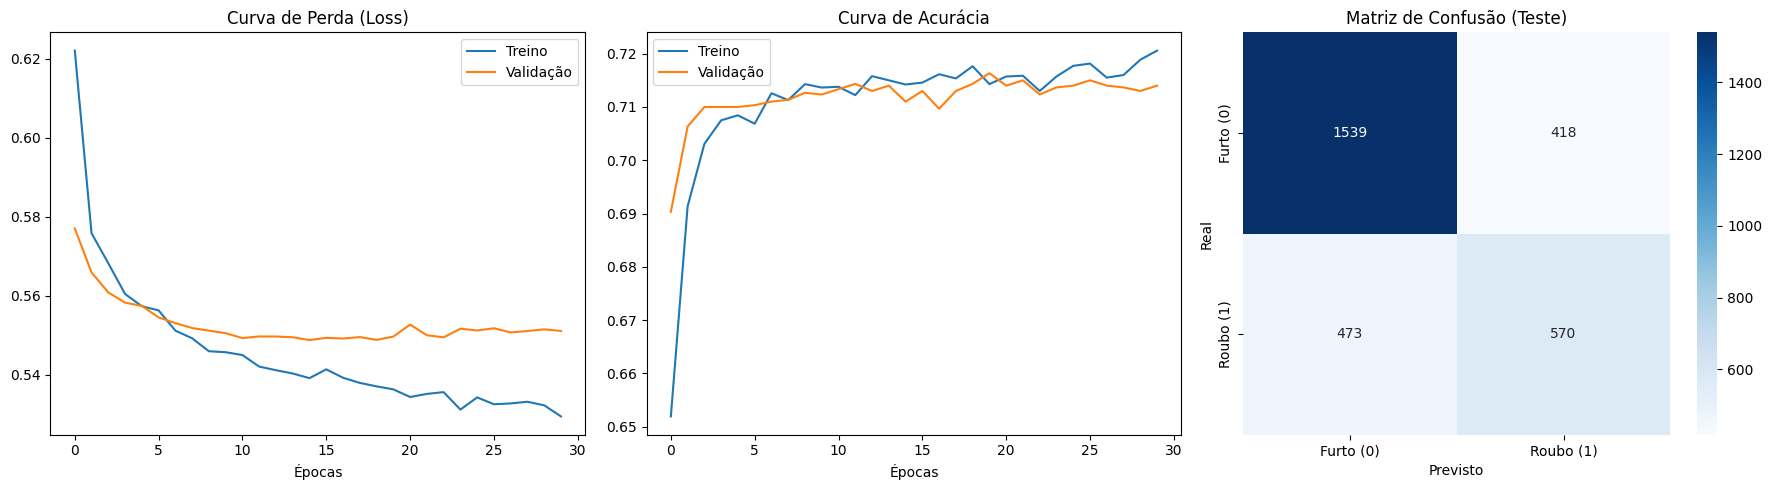

Modelo salvo como 'modelo_mlp.keras'!


In [11]:
# Escolha o modelo vencedor com base na tabela acima
modelo_final = mlp3
hist_final = hist3

probs_test = modelo_final.predict(X_test_proc, verbose=0)
preds_test = (probs_test >= 0.5).astype(int)

print("=== DESEMPENHO FINAL NO CONJUNTO DE TESTE ===")
print(f"Acurácia:  {accuracy_score(y_test, preds_test):.4f}")
print(f"Precision: {precision_score(y_test, preds_test):.4f}")
print(f"Recall:    {recall_score(y_test, preds_test):.4f}")
print(f"F1-Score:  {f1_score(y_test, preds_test):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(hist_final.history['loss'], label='Treino')
axes[0].plot(hist_final.history['val_loss'], label='Validação')
axes[0].set_title('Curva de Perda (Loss)')
axes[0].set_xlabel('Épocas')
axes[0].legend()

axes[1].plot(hist_final.history['accuracy'], label='Treino')
axes[1].plot(hist_final.history['val_accuracy'], label='Validação')
axes[1].set_title('Curva de Acurácia')
axes[1].set_xlabel('Épocas')
axes[1].legend()

cm = confusion_matrix(y_test, preds_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Furto (0)', 'Roubo (1)'],
            yticklabels=['Furto (0)', 'Roubo (1)'], ax=axes[2])
axes[2].set_title('Matriz de Confusão (Teste)')
axes[2].set_ylabel('Real')
axes[2].set_xlabel('Previsto')

plt.tight_layout()
plt.savefig("avaliacao_final_mlp.png", dpi=300)
plt.show()

modelo_final.save("modelo_mlp.keras")
print("Modelo salvo como 'modelo_mlp.keras'!")